In [1]:
import pandas as pd
import yaml
import os
import sys
sys.path.append('/workspace/src/')
from utils.helper_utils import split_annotations

In [2]:
nss = pd.read_csv("/workspace/data/NSS_metadata.csv", index_col=0, header=0)
wc = pd.read_csv("/workspace/data/whiteCAT_metadata.csv", index_col=0, header=0)
join = pd.concat([nss, wc])
join

,Filename,Dataset,Diagnosis,Age,Sex,Usage_original,Augmented,DatasetName,ID_format,ID,...,nssc_17,nssc_18,nssc_19,nssc_20,nssc_21,nssc_22,nssc_23,nssc_24,nssc_25,nssc_ext_final_complete
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
0,sub-NSS001_ses-01_T1w,NSS,SCHZ,43.000000,Male,testing,NaN,NaN,sub-NSS001,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,sub-NSS002_ses-01_T1w,NSS,SCHZ,53.000000,Female,testing,NaN,NaN,sub-NSS002,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,sub-NSS003_ses-01_T1w,NSS,SCHZ,26.000000,Male,testing,NaN,NaN,sub-NSS003,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,sub-NSS004_ses-01_T1w,NSS,SCHZ,49.000000,Female,testing,NaN,NaN,sub-NSS004,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,sub-NSS005_ses-01_T1w,NSS,SCHZ,32.000000,Male,testing,NaN,NaN,sub-NSS005,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,sub-whiteCAT130_ses-01_T1w,whiteCAT,SCHZ,27.167693,Female,testing,NaN,NaN,sub-whiteCAT130,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
158,sub-whiteCAT132_ses-01_T1w,whiteCAT,CTT,18.817248,Female,testing,NaN,NaN,sub-whiteCAT132,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
159,sub-whiteCAT133_ses-01_T1w,whiteCAT,SCHZ,59.737166,Female,testing,NaN,NaN,sub-whiteCAT133,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
with open("/workspace/experiment_config.yaml", 'r') as file:
    config = yaml.safe_load(file)

path_original="/workspace/data/full_metadata.csv"
meta = pd.read_csv(path_original, header=[0]).drop(columns=["Unnamed: 0", "Unnamed: 0.1", "Usage_original"])

In [3]:
config["data"]

{'data_dir': './data/',
 'data_format': 'csv',
 'metadata_path': './data/full_metadata.csv',
 'input_atlases': ['neuromorphometrics', 'suit', 'lpba40', 'cobra'],
 'diagnoses': ['HC, orange', 'MDD, blue', 'SCHZ, red', 'CTT, navy'],
 'resampling': 'hybrid',
 'resampling_method': '',
 'mtype': 'None',
 'train_proportion': 0.7,
 'train_test_split': {'remove_within_variable': ['Dataset'],
  'remove_variable_values': [['whiteCAT', 'NSS']],
  'test_on_subset': 'all',
  'extra_metadata_paths': ['/workspace/data/NSS_metadata.csv',
   '/workspace/data/whiteCAT_metadata.csv'],
  'train_valid_proportion': 0.8}}

In [10]:
plot_colors = {}
for i in range(0, len(config["data"]["diagnoses"]), 2):
    plot_colors[config["data"]["diagnoses"][i]] = config["data"]["diagnoses"][i+1]
plot_colors

{'HC, orange': 'MDD, blue', 'SCHZ, red': 'CTT, navy'}

In [4]:
split = config["data"]["train_test_split"]
split

{'remove_within_variable': ['Dataset', 'Sex'],
 'remove_variable_values': [['whiteCAT', 'NSS'], ['Male']],
 'test_on_subset': 'NSS',
 'extra_metadata_paths': ['/workspace/data/NSS_metadata.csv',
  '/workspace/data/whiteCAT_metadata.csv'],
 'train_valid_proportion': 0.8,
 'train_proportion': 0.7}

In [ ]:
def determine_split(split_config: dict, meta: pd.DataFrame):

    meta_split = {}

    if len(split_config["remove_within_variable"]) == 0:

        train_valid_df, test_df = split_annotations(annotations=meta, proportion=split_config["train_valid_proportion"])
        meta_split =  {"train_valid": train_valid_df, "test": test_df,}

    else: 
        removed_subsets = []
        
        for idx, var in enumerate(split_config["remove_within_variable"]): 
            remove_subset = meta[meta[var].isin(split_config["remove_variable_values"][idx])]
            removed_subsets.append(remove_subset)

        removed_data = pd.concat(removed_subsets).drop_duplicates(keep="first")
        removed_samples = removed_data["Filename"].to_list()

        filtered_df = meta[~meta["Filename"].isin(removed_samples)]
        
        train_valid_df, test_df = split_annotations(annotations=filtered_df, proportion=split_config["train_valid_proportion"])
        meta_split =  {"train_valid": train_valid_df, "test": test_df,}

        if split_config["test_on_subset"] == "all":
            meta_split["hold_out_test"] = removed_data
        else: 
            if split_config["test_on_subset"] in split_config["remove_within_variable"]:
                sub_idx = split_config["remove_within_variable"].index(split_config["test_on_subset"])
                meta_split["hold_out_test"] = removed_subsets[sub_idx]
            else: 
                for sub_idx, var_vals in enumerate(split_config["remove_variable_values"]): 
                    if split_config["test_on_subset"] in var_vals:
                        _hold_out = removed_subsets[sub_idx]

                        hold_out = _hold_out[_hold_out[split_config["remove_within_variable"][sub_idx]].isin([split_config["test_on_subset"]])]
                       
                        meta_split["hold_out_test"] = hold_out

    for purpose, df in meta_split.items(): 
        print(f"\n Shuffled metadata for {purpose}")
        print(f"Shape: {df.shape}")
        print(f"{df.head(5)}")

    return meta_split


In [ ]:
out = determine_split(split, meta)


 Shuffled metadata for train_valid
Shape: (908, 6)
              Filename Dataset Diagnosis   Age     Sex  Sex_int
0  IXI078-Guys-0751-T1     IXI        HC  47.4  Female        0
1  IXI140-Guys-0787-T1     IXI        HC  46.7  Female        0
2  IXI321-Guys-0903-T1     IXI        HC  73.1  Female        0
3  IXI312-Guys-0887-T1     IXI        HC  77.5  Female        0
4  IXI193-Guys-0810-T1     IXI        HC  74.0  Female        0

 Shuffled metadata for test
Shape: (226, 6)
              Filename Dataset Diagnosis   Age     Sex  Sex_int
0  IXI397-Guys-0953-T1     IXI        HC  69.8  Female        0
1    IXI226-HH-1618-T1     IXI        HC  60.6  Female        0
2  IXI403-Guys-0965-T1     IXI        HC  71.6  Female        0
3   IXI290-IOP-0874-T1     IXI        HC  64.2  Female        0
4    IXI102-HH-1416-T1     IXI        HC  43.5  Female        0

 Shuffled metadata for hold_out_test
Shape: (117, 6)
                   Filename Dataset Diagnosis   Age     Sex  Sex_int
2748  sub-NS

In [4]:
atlases = config["data"]["input_atlases"]
atlases

['neuromorphometrics', 'suit', 'lpba40', 'cobra']

In [ ]:
def get_atlas_map(atlases):
    atlas_map = {}
    for atlas in sorted(atlases): 
        caps = atlas.title()

        if f"[{caps[0]}]" in atlas_map.keys():
            atlas_map[f"[{caps[:1]}]"] = atlas
        else: 
            atlas_map[f"[{caps[0]}]"] = atlas
    return atlas_map



In [6]:
nss_data = pd.read_csv("/workspace/data/NSS_metadata.csv", header=0, index_col=0)
whitecat_data = pd.read_csv("/workspace/data/whiteCAT_metadata.csv", header=0, index_col=0)

In [7]:
from utils.downstream_utils import rename_nss_wc

zi_data = rename_nss_wc(nss_data, whitecat_data)

In [6]:
zi_data

,Dataset,Diagnosis,Age,Sex,catatonia_icd11_v1,Olanzapin,panss_p,panss_n,panss_g,panss_total,...,ncrs_behavior,ncrs_total,nss_total,nss_motor,gaf_score,bis11_attentional,bis11_motor,bis11_nonplanning,bis11_total,Codiagnosis
Filename,,,,,,,,,,,,,,,,,,,,,
sub-NSS001_ses-01_T1w,NSS,SCHZ,43.000000,Male,0.0,17.000000,11.0,18.0,25.0,54.0,...,3.0,6.0,16.0,8.0,50.0,11.0,20.0,26.0,57.0,F20.0
sub-NSS002_ses-01_T1w,NSS,SCHZ,53.000000,Female,0.0,29.200000,12.0,21.0,41.0,74.0,...,0.0,1.0,16.0,8.0,80.0,12.0,13.0,27.0,52.0,F20.0
sub-NSS003_ses-01_T1w,NSS,SCHZ,26.000000,Male,0.0,7.500000,24.0,17.0,29.0,70.0,...,0.0,2.0,7.0,5.0,60.0,9.0,12.0,27.0,46.0,F20.0
sub-NSS004_ses-01_T1w,NSS,SCHZ,49.000000,Female,0.0,13.000000,10.0,20.0,31.0,61.0,...,0.0,0.0,16.0,8.0,90.0,14.0,12.0,24.0,50.0,F20.0
sub-NSS005_ses-01_T1w,NSS,SCHZ,32.000000,Male,0.0,10.600000,7.0,15.0,24.0,46.0,...,0.0,0.0,19.0,6.0,90.0,10.0,8.0,24.0,42.0,F20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sub-whiteCAT130_ses-01_T1w,whiteCAT,SCHZ,27.167693,Female,0.0,0.000000,7.0,13.0,27.0,47.0,...,3.0,7.0,6.0,0.0,50.0,16.0,11.0,15.0,47.0,F33.1
sub-whiteCAT132_ses-01_T1w,whiteCAT,CTT,18.817248,Female,1.0,112.580918,22.0,24.0,45.0,91.0,...,4.0,10.0,14.0,0.0,38.0,21.0,15.0,21.0,60.0,F32.3
sub-whiteCAT133_ses-01_T1w,whiteCAT,SCHZ,59.737166,Female,0.0,1.785714,10.0,20.0,50.0,80.0,...,3.0,6.0,19.0,2.0,38.0,20.0,12.0,19.0,57.0,F33.2


In [12]:
import numpy as np

def correct_nss_wc_labels(joined_df) -> pd.DataFrame:
    # The diagnosis labels are incorrect in the NSS and whiteCAT dataframes. We correct them from the total metadata.
    diagnosis_map = meta[["Filename", "Diagnosis"]].copy()
    diagnosis_map.rename(columns={"Diagnosis": "correct_diagnosis"}, inplace=True)
    joined_df = joined_df.merge(diagnosis_map, on="Filename", how="left")
    joined_df["Diagnosis"] = joined_df["correct_diagnosis"].fillna(joined_df["Diagnosis"])
    
    return joined_df.drop(columns=["correct_diagnosis"])

correct_zi_data = correct_nss_wc_labels(zi_data)


def correct_labels(df):
    df_extra_col = df.copy()
    df_extra_col["Diagnosis_extra"] = ""

    for idx, row in df_extra_col.iterrows():
        if "F2" in str(row["Codiagnosis"]):
            df_extra_col.loc[idx, "Diagnosis_extra"] = "SCHZ"
        if "F3" in str(row["Codiagnosis"]): 
            df_extra_col.loc[idx, "Diagnosis_extra"] = "MDD"

    return df_extra_col

correct_ext_zi_data = correct_labels(correct_zi_data)

In [14]:
correct_ext_zi_data.Diagnosis_extra.unique()

array(['SCHZ', 'MDD'], dtype=object)

In [15]:
correct_ext_zi_data.to_csv("/workspace/data/extended_metadata.csv")

## NSS and WC data


/tmp/ipykernel_1757691/3956655432.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Diagnosis", y=score, data=gaf_sub,
/tmp/ipykernel_1757691/3956655432.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Diagnosis", y=score, data=gaf_sub,
/tmp/ipykernel_1757691/3956655432.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Diagnosis", y=score, data=gaf_sub,
/tmp/ipykernel_1757691/3956655432.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

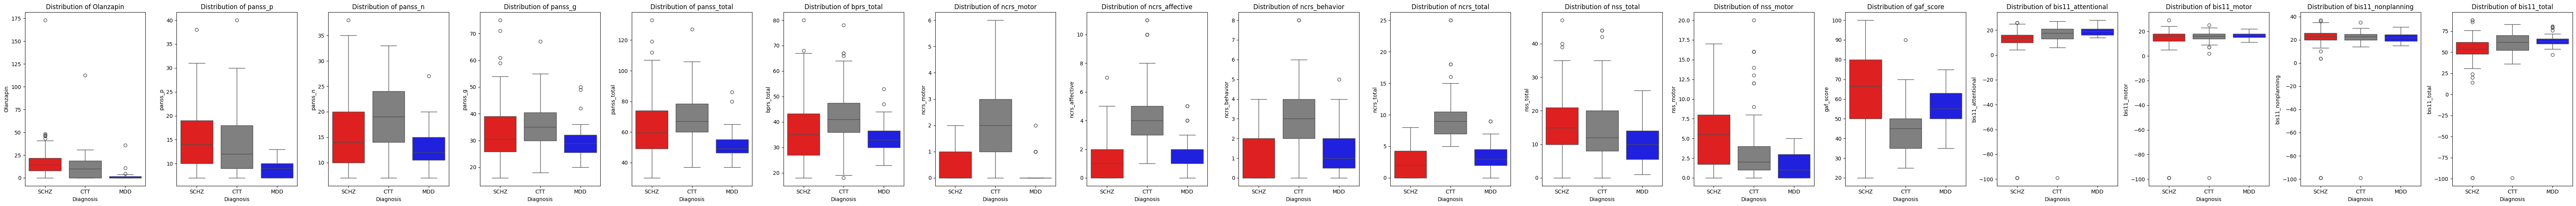

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data without error handling (assuming it is now available)
nsswc = pd.read_csv("/workspace/data/extended_metadata.csv", index_col=0)

# Filter for the diagnoses of interest: "SCHZ" and "CTT"
gaf_sub = nsswc[nsswc["Diagnosis"].isin(["SCHZ", "CTT", "MDD"])].copy()

scores = ['Olanzapin', 'panss_p', 'panss_n', 'panss_g', 'panss_total', 'bprs_total', 'ncrs_motor', 'ncrs_affective', 'ncrs_behavior', 'ncrs_total', 'nss_total', 'nss_motor', 'gaf_score', 'bis11_attentional', 'bis11_motor', 'bis11_nonplanning', 'bis11_total']

#scores = ["gaf_score", "ncrs_total", "Olanzapin", "panss_total", "nss_total"]
# Create a figure with two subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, len(scores), figsize=(4*len(scores), 6), sharey=False)

for idx, score in enumerate(scores):
    # --- First Subplot: gaf_score ---
    sns.boxplot(x="Diagnosis", y=score, data=gaf_sub, 
                # Reusing the requested colors (red for SCHZ, gray for CTT)
                palette={"SCHZ": "red", "MDD": "blue", "CTT": "gray"}, ax=axes[idx])
    axes[idx].set_title(f"Distribution of {score}")
    axes[idx].set_xlabel("Diagnosis")
    #axes[idx].set_ylabel(f"{score}")

# # --- Second Subplot: ncrs_total ---
# sns.boxplot(x="Diagnosis", y="ncrs_total", data=gaf_sub, 
#             # Reusing the requested colors (red for SCHZ, gray for CTT)
#             palette={"SCHZ": "red", "CTT": "gray", "MDD": "blue",}, ax=axes[1])
# axes[1].set_title("Distribution of NCRS Total Score")
# axes[1].set_xlabel("Diagnosis")
# axes[1].set_ylabel("NCRS Total Score")

# # --- Second Subplot: ncrs_total ---
# sns.boxplot(x="Diagnosis", y="Olanzapin", data=gaf_sub, 
#             # Reusing the requested colors (red for SCHZ, gray for CTT)
#             palette={"SCHZ": "red", "CTT": "gray", "MDD": "blue",}, ax=axes[2])
# axes[2].set_title("Distribution of Olanzapine Score")
# axes[2].set_xlabel("Diagnosis")
# axes[2].set_ylabel("Olanzapine")

# Adjust layout
#plt.suptitle("Comparison of Key Score Distributions for SCHZ and CTT", fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Make room for suptitle
# plt.savefig(f"/workspace/src/distributions_ncrs_gaf_olz.png")
# plt.savefig(f"/workspace/src/distributions_ncrs_gaf_olz.svg")
plt.show()


/tmp/ipykernel_1497163/1415351689.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Diagnosis', y='Age', ax=axes[0], palette='Set2')


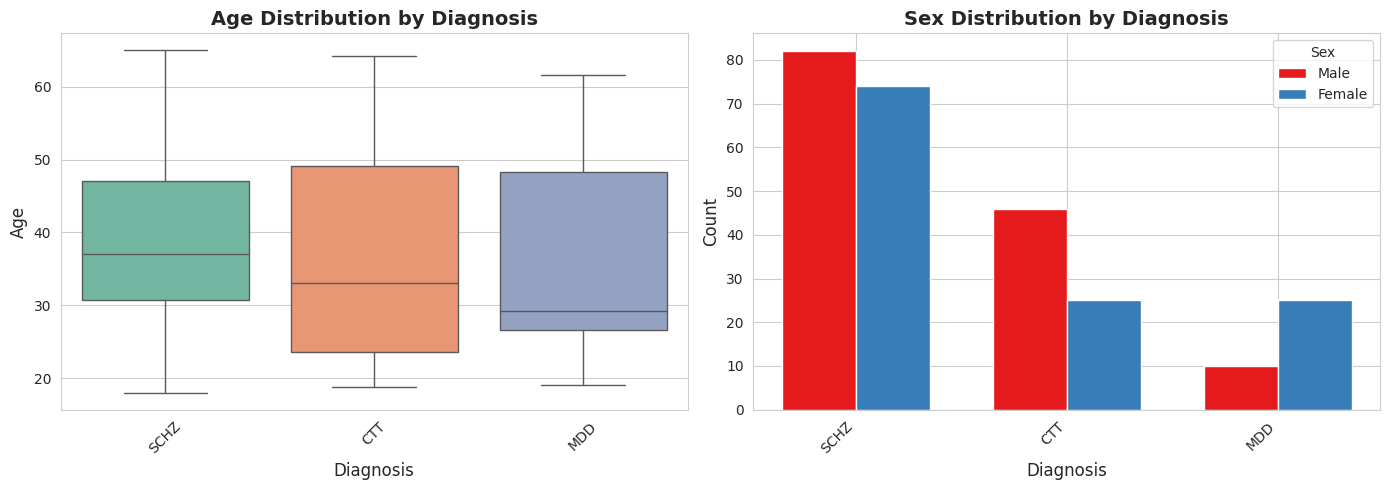

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data without error handling (assuming it is now available)
nsswc = pd.read_csv("/workspace/data/extended_metadata.csv", index_col=0)

df = nsswc.copy()

# Assuming your dataframe is called 'df'
# df = pd.read_csv('your_data.csv')  # Load your data

# Set style
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot: Age distribution by Diagnosis
sns.boxplot(data=df, x='Diagnosis', y='Age', ax=axes[0], palette='Set2')
axes[0].set_title('Age Distribution by Diagnosis', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Diagnosis', fontsize=12)
axes[0].set_ylabel('Age', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# 2. Bar plot: Sex counts by Diagnosis
sex_counts = df.groupby(['Diagnosis', 'Sex']).size().reset_index(name='Count')
diagnoses = df['Diagnosis'].unique()
x = range(len(diagnoses))
width = 0.35

# Get unique sex values
sex_values = df['Sex'].unique()
colors = sns.color_palette('Set1', n_colors=len(sex_values))

# Plot bars for each sex
for i, sex in enumerate(sex_values):
    sex_data = sex_counts[sex_counts['Sex'] == sex]
    counts = [sex_data[sex_data['Diagnosis'] == d]['Count'].values[0] 
              if len(sex_data[sex_data['Diagnosis'] == d]) > 0 else 0 
              for d in diagnoses]
    axes[1].bar([p + width * i for p in x], counts, width, 
                label=sex, color=colors[i])

axes[1].set_title('Sex Distribution by Diagnosis', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Diagnosis', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_xticks([p + width * (len(sex_values) - 1) / 2 for p in x])
axes[1].set_xticklabels(diagnoses, rotation=45, ha='right')
axes[1].legend(title='Sex')

plt.tight_layout()
plt.show()
plt.close()

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations

# Load and filter data
df = pd.read_csv("/workspace/data/full_metadata.csv", header=0, index_col=0)

df.loc[(df["Dataset"] == "NU") & (df["Diagnosis"] == "SCHZ"), "Age"] = 33.8
df.loc[(df["Dataset"] == "NU") & (df["Diagnosis"] == "HC"), "Age"] = 31.4

# 1. Define the Age Bins (adjust these to fit your data's actual age range)
age_bins = [0, 18, 30, 45, 60, 75, 100] # Example: 0-18, 18-30, 30-45, etc.
bin_labels = ['0-17', '18-29', '30-44', '45-59', '60-74', '75+']

# 2. Create a new binned column
df['Age_Bin'] = pd.cut(df['Age'], bins=age_bins, labels=bin_labels, right=False)

df

,Unnamed: 0,Filename,Dataset,Diagnosis,Age,Sex,Usage_original,Sex_int,Age_Bin
0,0,IXI426-IOP-1011-T1,IXI,HC,41.2,Female,training,0,30-44
1,1,IXI571-IOP-1154-T1,IXI,HC,56.6,Female,training,0,45-59
2,2,IXI170-Guys-0843-T1,IXI,HC,50.2,Female,training,0,45-59
3,3,IXI054-Guys-0707-T1,IXI,HC,60.8,Female,training,0,60-74
4,4,IXI196-Guys-0805-T1,IXI,HC,47.8,Female,training,0,45-59
...,...,...,...,...,...,...,...,...,...
2887,709,sub-NSS126_ses-01_T1w,NSS,SCHZ,37.0,Female,testing,0,30-44
2888,710,sub-NSS127_ses-01_T1w,NSS,SCHZ,28.0,Female,testing,0,18-29
2889,711,sub-NSS128_ses-01_T1w,NSS,SCHZ,44.0,Male,testing,1,30-44
2890,712,sub-NSS129_ses-01_T1w,NSS,CTT,41.0,Female,testing,0,30-44


/tmp/ipykernel_1497163/3920399827.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Diagnosis', y='Age', ax=axes[0], palette='Set2')


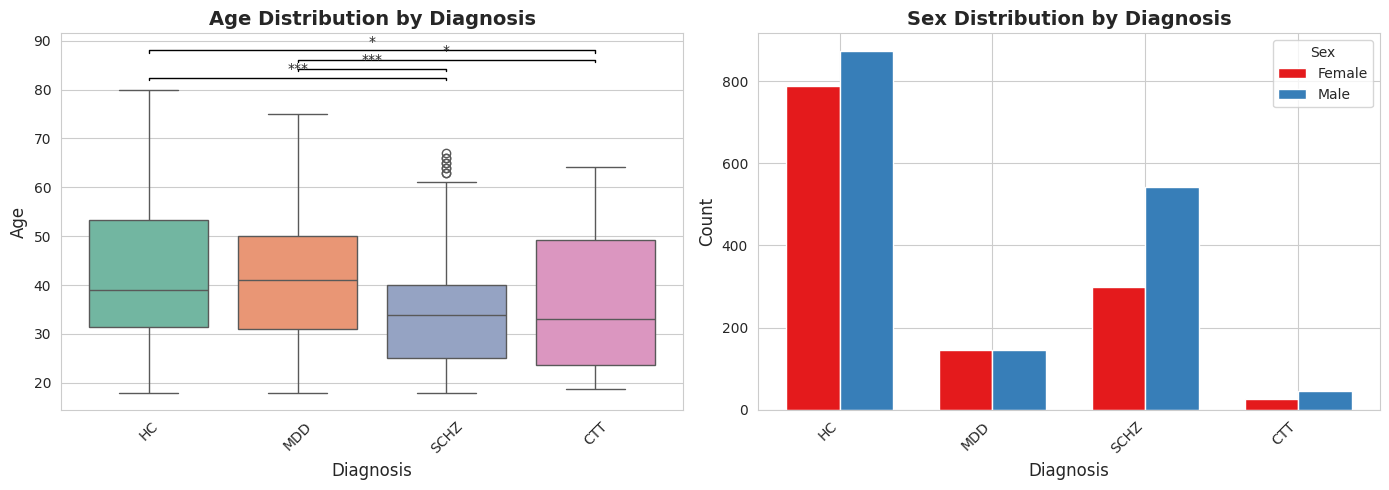


Pairwise comparisons (Mann-Whitney U test):
HC vs SCHZ: p = 0.0000
MDD vs SCHZ: p = 0.0000
MDD vs CTT: p = 0.0113
HC vs CTT: p = 0.0134


In [32]:

# Set style
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot: Age distribution by Diagnosis with statistical annotations
sns.boxplot(data=df, x='Diagnosis', y='Age', ax=axes[0], palette='Set2')
axes[0].set_title('Age Distribution by Diagnosis', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Diagnosis', fontsize=12)
axes[0].set_ylabel('Age', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# Perform pairwise statistical tests (Mann-Whitney U test)
diagnoses = df['Diagnosis'].unique()
pairs = list(combinations(range(len(diagnoses)), 2))
y_max = df['Age'].max()
y_range = df['Age'].max() - df['Age'].min()
h = y_range * 0.03  # Height increment for brackets

# Calculate p-values for all pairs
significant_pairs = []
for i, (idx1, idx2) in enumerate(pairs):
    group1 = df[df['Diagnosis'] == diagnoses[idx1]]['Age'].dropna()
    group2 = df[df['Diagnosis'] == diagnoses[idx2]]['Age'].dropna()
    
    if len(group1) > 0 and len(group2) > 0:
        statistic, p_value = stats.mannwhitneyu(group1, group2, alternative='two-sided')
        
        # Only annotate significant differences (p < 0.05)
        if p_value < 0.05:
            significant_pairs.append((idx1, idx2, p_value))

# Sort by p-value to prioritize most significant
significant_pairs.sort(key=lambda x: x[2])

# Annotate significant pairs (limit to avoid overcrowding)
max_annotations = min(6, len(significant_pairs))
for i, (idx1, idx2, p_value) in enumerate(significant_pairs[:max_annotations]):
    y_pos = y_max + h * (i + 1)
    
    # Format p-value
    if p_value < 0.001:
        text = '***'
    elif p_value < 0.01:
        text = '**'
    elif p_value < 0.05:
        text = '*'
    else:
        text = 'ns'
    
    # Draw bracket
    axes[0].plot([idx1, idx1, idx2, idx2], 
                 [y_pos, y_pos + h*0.3, y_pos + h*0.3, y_pos], 
                 'k-', lw=1)
    axes[0].text((idx1 + idx2) / 2, y_pos + h*0.5, text, 
                ha='center', va='bottom', fontsize=10)

# 2. Bar plot: Sex counts by Diagnosis
sex_counts = df.groupby(['Diagnosis', 'Sex']).size().reset_index(name='Count')
x = range(len(diagnoses))
width = 0.35

# Get unique sex values
sex_values = df['Sex'].unique()
colors = sns.color_palette('Set1', n_colors=len(sex_values))

# Plot bars for each sex
for i, sex in enumerate(sex_values):
    sex_data = sex_counts[sex_counts['Sex'] == sex]
    counts = [sex_data[sex_data['Diagnosis'] == d]['Count'].values[0] 
              if len(sex_data[sex_data['Diagnosis'] == d]) > 0 else 0 
              for d in diagnoses]
    axes[1].bar([p + width * i for p in x], counts, width, 
                label=sex, color=colors[i])

axes[1].set_title('Sex Distribution by Diagnosis', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Diagnosis', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_xticks([p + width * (len(sex_values) - 1) / 2 for p in x])
axes[1].set_xticklabels(diagnoses, rotation=45, ha='right')
axes[1].legend(title='Sex')

plt.tight_layout()
plt.show()

# Print all pairwise comparisons for reference
print("\nPairwise comparisons (Mann-Whitney U test):")
print("=" * 60)
for idx1, idx2, p_value in significant_pairs:
    print(f"{diagnoses[idx1]} vs {diagnoses[idx2]}: p = {p_value:.4f}")